# 时频变换算法交互式分析工具

本Notebook用于验证和调优各种时频变换算法的处理效果。

## 功能特点
- 支持15种时频变换算法
- 交互式参数调整
- 去直流/去趋势预处理（防止近零Hz异常大值）
- 参数调整范围标注

## 测试数据
```
Z:\TC1-DC-A-2m-110-270-0625\400K12\2\2\二阶波-Δ2\t2-10ms210ms\0v20ms-20v10ms-22v10ms
```

In [1]:
# ========================================
# 1. 环境配置与依赖导入
# ========================================
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import spectrogram, hilbert, welch
import pywt
import warnings
warnings.filterwarnings('ignore')

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (14, 8)

print('环境配置完成!')

环境配置完成!


In [2]:
# ========================================
# 2. 数据加载模块
# ========================================

def generate_test_signal(fs=10000, duration=0.5):
    """
    生成测试信号（用于快速验证算法）
    包含: 直流偏移 + 低频趋势 + 100Hz中频 + 500Hz高频(调幅) + 瞬态冲击 + 噪声
    """
    t = np.linspace(0, duration, int(fs * duration))
    
    dc_offset = 5.0  # 直流偏移
    trend = 0.5 * t  # 低频趋势
    signal_mid = 2.0 * np.sin(2 * np.pi * 100 * t)  # 100Hz
    am_signal = 1.0 * np.sin(2 * np.pi * 5 * t)
    signal_high = (1.0 + 0.5 * am_signal) * np.sin(2 * np.pi * 500 * t)  # 500Hz调幅
    
    impulses = np.zeros_like(t)
    for it in [0.1, 0.25, 0.4]:
        idx = int(it * fs)
        if idx < len(impulses):
            impulses[idx] = 10.0
    
    noise = 0.3 * np.random.randn(len(t))
    x = dc_offset + trend + signal_mid + signal_high + impulses + noise
    
    return t, x


def preprocess_signal(x, remove_dc=True, detrend=True):
    """
    信号预处理：去直流和去趋势
    重要：防止近零Hz出现异常大值
    """
    x = np.asarray(x, dtype=float)
    if remove_dc:
        x = x - np.mean(x)
    if detrend and len(x) > 10:
        x = signal.detrend(x)
    return x

print('数据加载模块已定义')

数据加载模块已定义


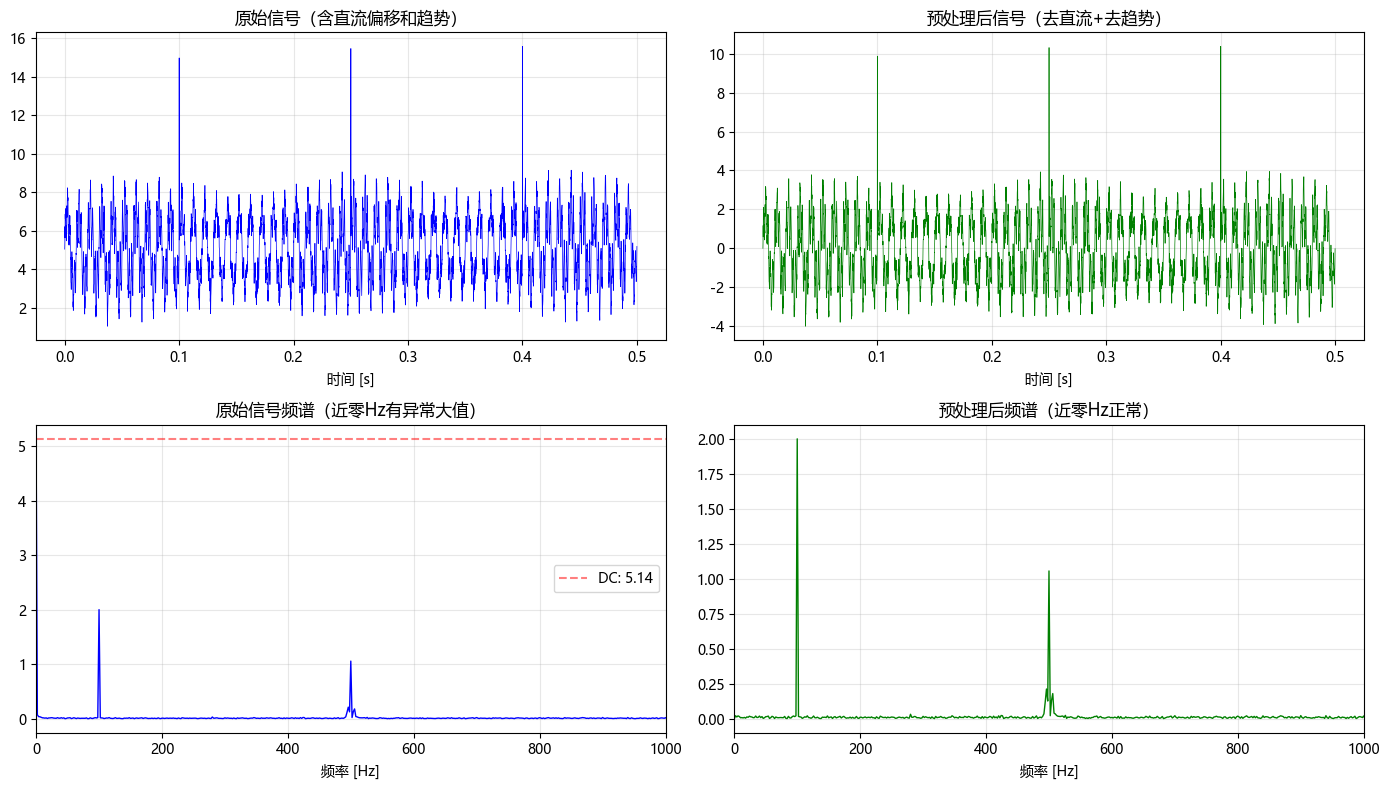

原始信号均值: 5.1358
处理后信号均值: -0.000000


In [3]:
# ========================================
# 3. 生成测试数据
# ========================================

FS = 10000  # 采样频率 (Hz)
DURATION = 0.5  # 信号时长 (秒) - 缩短以提高执行速度

t, raw_signal = generate_test_signal(fs=FS, duration=DURATION)
processed_signal = preprocess_signal(raw_signal, remove_dc=True, detrend=True)

# 可视化对比
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(t, raw_signal, 'b-', linewidth=0.5)
axes[0, 0].set_title('原始信号（含直流偏移和趋势）')
axes[0, 0].set_xlabel('时间 [s]'); axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(t, processed_signal, 'g-', linewidth=0.5)
axes[0, 1].set_title('预处理后信号（去直流+去趋势）')
axes[0, 1].set_xlabel('时间 [s]'); axes[0, 1].grid(True, alpha=0.3)

# 原始信号频谱
fft_raw = np.fft.rfft(raw_signal)
freqs_raw = np.fft.rfftfreq(len(raw_signal), d=1/FS)
mag_raw = np.abs(fft_raw) / len(raw_signal)
mag_raw[1:] *= 2
axes[1, 0].plot(freqs_raw, mag_raw, 'b-', linewidth=1)
axes[1, 0].set_title('原始信号频谱（近零Hz有异常大值）')
axes[1, 0].set_xlabel('频率 [Hz]'); axes[1, 0].set_xlim([0, 1000])
axes[1, 0].axhline(y=mag_raw[0], color='r', linestyle='--', alpha=0.5, label='DC: %.2f' % mag_raw[0])
axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

# 处理后频谱
fft_proc = np.fft.rfft(processed_signal)
freqs_proc = np.fft.rfftfreq(len(processed_signal), d=1/FS)
mag_proc = np.abs(fft_proc) / len(processed_signal)
mag_proc[1:] *= 2
axes[1, 1].plot(freqs_proc, mag_proc, 'g-', linewidth=1)
axes[1, 1].set_title('预处理后频谱（近零Hz正常）')
axes[1, 1].set_xlabel('频率 [Hz]'); axes[1, 1].set_xlim([0, 1000])
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

print('原始信号均值: %.4f' % np.mean(raw_signal))
print('处理后信号均值: %.6f' % np.mean(processed_signal))

---

# 时频变换算法详解

STFT (短时傅里叶变换) 参数对比
参数说明:
  nperseg (窗长): 控制频率分辨率
    - 小窗长(64): 高时间分辨率，低频率分辨率
    - 大窗长(1024): 低时间分辨率，高频率分辨率



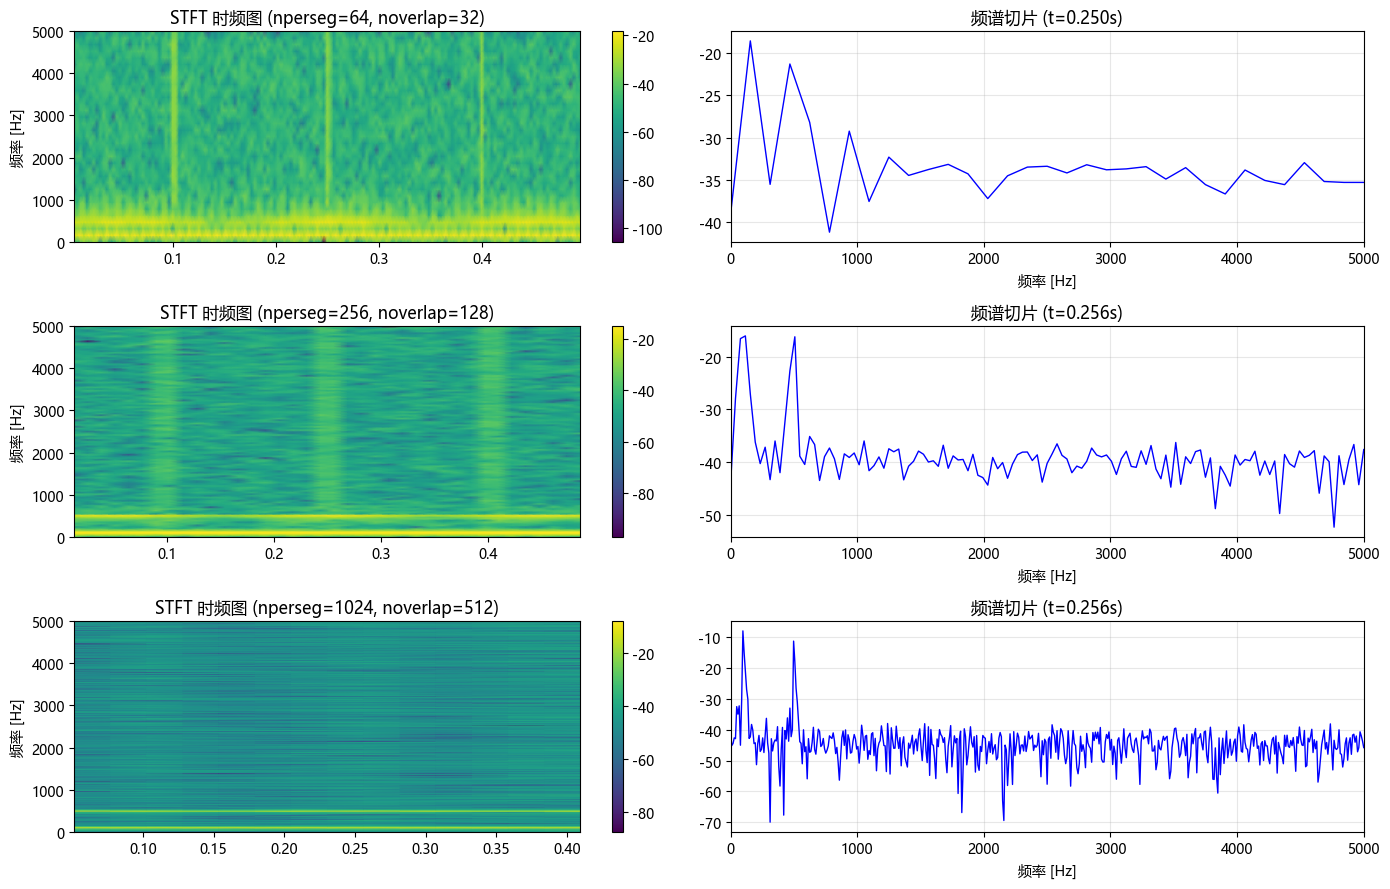

In [4]:
# ========================================
# 4. 算法1: STFT (短时傅里叶变换)
# ========================================

def plot_stft_comparison(x, fs, nperseg_list=[64, 256, 1024], noverlap_ratio=0.5):
    """
    参数调整说明:
    - nperseg (窗长): 范围16~65536，越大频率分辨率越高
    - noverlap (重叠): 推荐nperseg的50%~75%
    """
    x = preprocess_signal(x)
    n = len(nperseg_list)
    fig, axes = plt.subplots(n, 2, figsize=(14, 3*n))
    if n == 1: axes = axes.reshape(1, -1)
    
    for i, nperseg in enumerate(nperseg_list):
        noverlap = int(nperseg * noverlap_ratio)
        f, t_stft, Zxx = spectrogram(x, fs=fs, nperseg=nperseg, noverlap=noverlap)
        
        im1 = axes[i, 0].pcolormesh(t_stft, f, 10*np.log10(Zxx+1e-12), shading='gouraud')
        axes[i, 0].set_title('STFT 时频图 (nperseg=%d, noverlap=%d)' % (nperseg, noverlap))
        axes[i, 0].set_ylabel('频率 [Hz]')
        plt.colorbar(im1, ax=axes[i, 0])
        
        slice_idx = len(t_stft) // 2
        axes[i, 1].plot(f, 10*np.log10(Zxx[:, slice_idx]+1e-12), 'b-', linewidth=1)
        axes[i, 1].set_title('频谱切片 (t=%.3fs)' % t_stft[slice_idx])
        axes[i, 1].set_xlabel('频率 [Hz]'); axes[i, 1].set_xlim([0, fs/2])
        axes[i, 1].grid(True, alpha=0.3)
    
    plt.tight_layout(); plt.show()

print('=' * 60)
print('STFT (短时傅里叶变换) 参数对比')
print('=' * 60)
print('参数说明:')
print('  nperseg (窗长): 控制频率分辨率')
print('    - 小窗长(64): 高时间分辨率，低频率分辨率')
print('    - 大窗长(1024): 低时间分辨率，高频率分辨率')
print('')
plot_stft_comparison(processed_signal, FS, nperseg_list=[64, 256, 1024])

CWT (连续小波变换)
小波基选择:
  cmor1.5-1.0: 标准Morlet小波，适合一般信号
  cmor2.0-1.0: 更窄带宽，高频率分辨率
  mexh: Mexico草帽小波
  gaus4: 高斯小波4阶



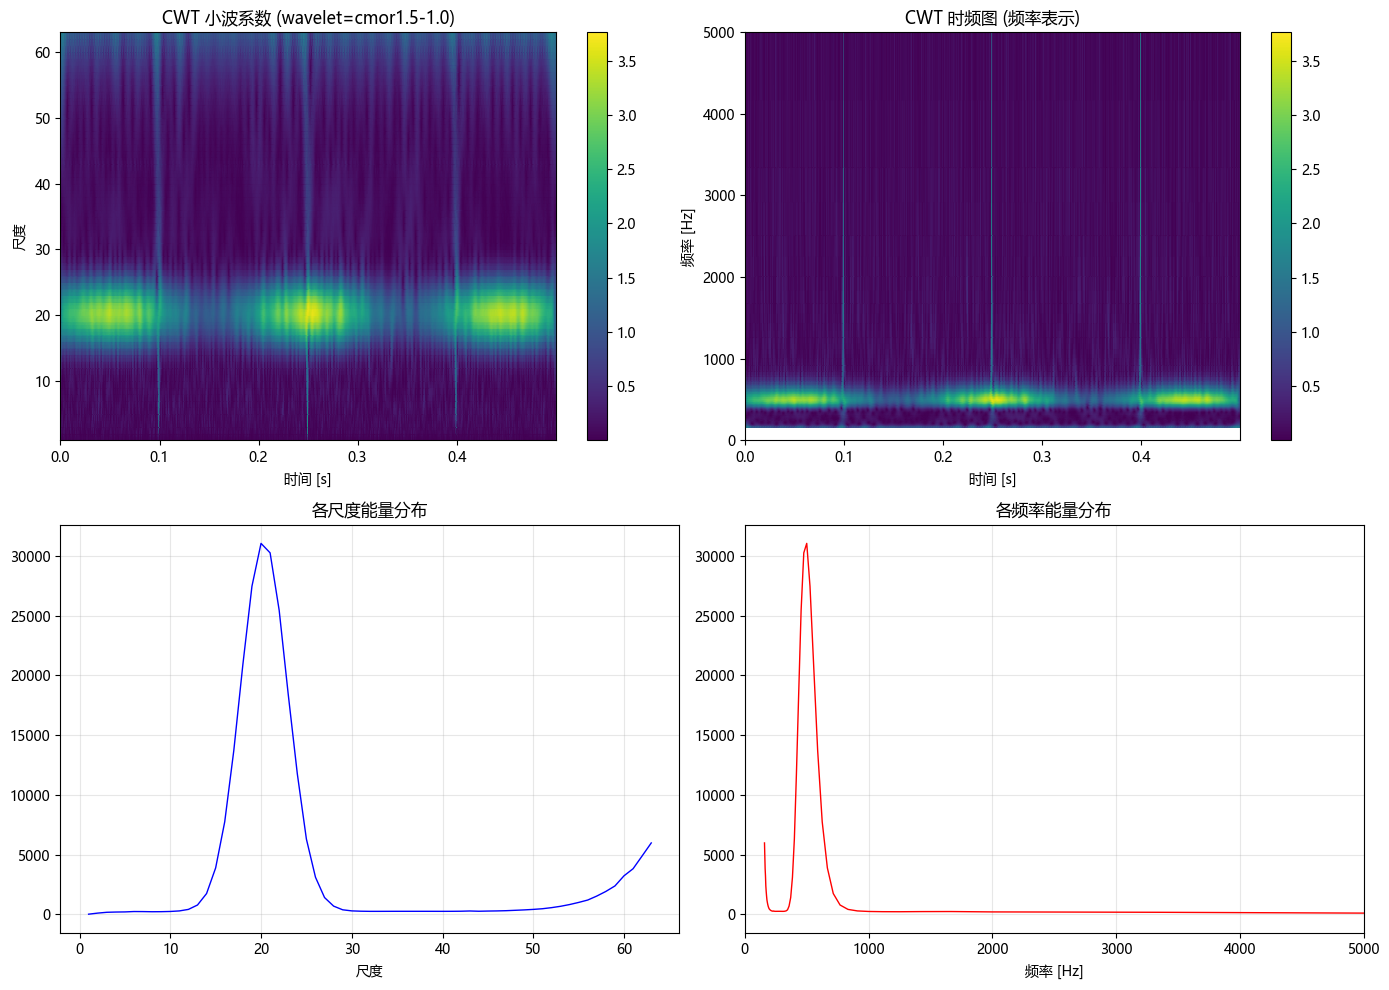

In [5]:
# ========================================
# 5. 算法2: CWT (连续小波变换)
# ========================================

def plot_cwt_comparison(x, fs, wavelet='cmor1.5-1.0', scales_range=(1, 64)):
    """
    参数调整说明:
    - wavelet (小波基): cmor1.5-1.0(通用), cmor2.0-0.5(高频率分辨率)
    - scales: 范围1~len(x)/4，小尺度对应高频
    """
    x = preprocess_signal(x)
    scales = np.arange(scales_range[0], min(scales_range[1], len(x)//8))
    coef, freqs = pywt.cwt(x, scales, wavelet, sampling_period=1.0/fs)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    t_wave = np.arange(x.shape[0]) / fs
    
    im1 = axes[0, 0].pcolormesh(t_wave, scales, np.abs(coef), shading='gouraud')
    axes[0, 0].set_title('CWT 小波系数 (wavelet=%s)' % wavelet)
    axes[0, 0].set_xlabel('时间 [s]'); axes[0, 0].set_ylabel('尺度')
    plt.colorbar(im1, ax=axes[0, 0])
    
    im2 = axes[0, 1].pcolormesh(t_wave, freqs, np.abs(coef), shading='gouraud')
    axes[0, 1].set_title('CWT 时频图 (频率表示)')
    axes[0, 1].set_xlabel('时间 [s]'); axes[0, 1].set_ylabel('频率 [Hz]')
    axes[0, 1].set_ylim([0, fs/2]); plt.colorbar(im2, ax=axes[0, 1])
    
    energy_per_scale = np.sum(np.abs(coef)**2, axis=1)
    axes[1, 0].plot(scales, energy_per_scale, 'b-', linewidth=1)
    axes[1, 0].set_title('各尺度能量分布')
    axes[1, 0].set_xlabel('尺度'); axes[1, 0].grid(True, alpha=0.3)
    
    energy_per_freq = np.sum(np.abs(coef)**2, axis=1)
    axes[1, 1].plot(freqs, energy_per_freq, 'r-', linewidth=1)
    axes[1, 1].set_title('各频率能量分布')
    axes[1, 1].set_xlabel('频率 [Hz]'); axes[1, 1].set_xlim([0, fs/2])
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout(); plt.show()

print('=' * 60)
print('CWT (连续小波变换)')
print('=' * 60)
print('小波基选择:')
print('  cmor1.5-1.0: 标准Morlet小波，适合一般信号')
print('  cmor2.0-1.0: 更窄带宽，高频率分辨率')
print('  mexh: Mexico草帽小波')
print('  gaus4: 高斯小波4阶')
print('')
plot_cwt_comparison(processed_signal, FS)

DWT / WPT (离散/小波包变换)
小波基: db4(通用), db8(平滑), sym4(对称)
层数: 3层(8带), 5层(32带), 6层(64带)



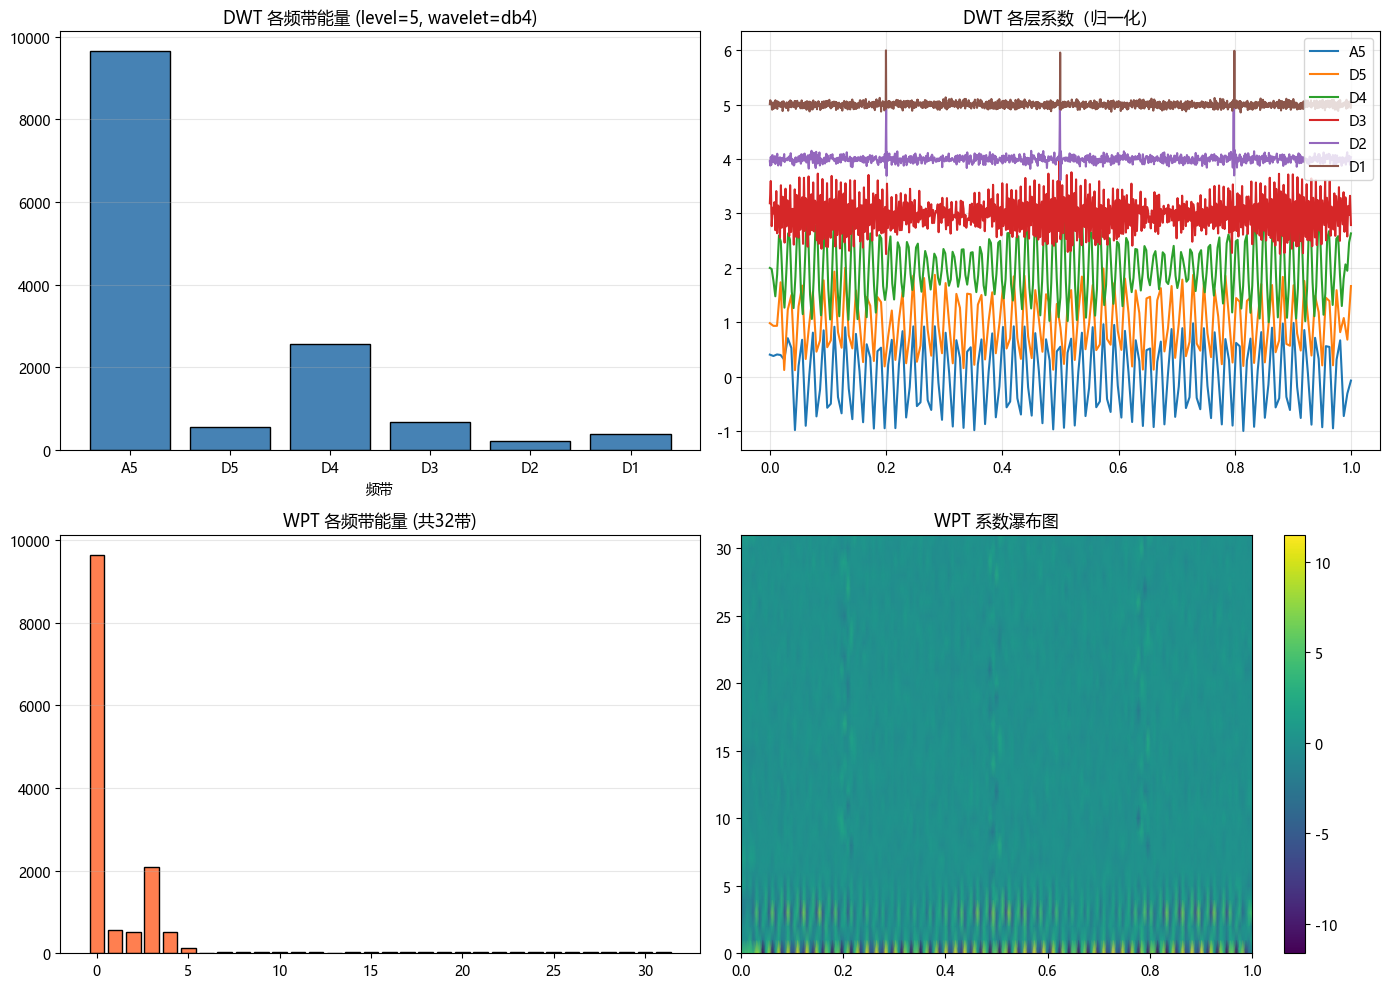

In [6]:
# ========================================
# 6. 算法3&4: DWT / WPT (离散小波变换)
# ========================================

def plot_dwt_wpt(x, wavelet='db4', max_level=None):
    """
    参数调整说明:
    - wavelet: db4(通用), db8(平滑), sym4(对称), coif2(正则)
    - level: 分解层数，3~6层推荐
    """
    x = preprocess_signal(x)
    N = len(x)
    if max_level is None:
        max_level = min(pywt.dwt_max_level(N, wavelet), 5)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    coeffs = pywt.wavedec(x, wavelet, level=max_level)
    labels = ['A%d' % max_level] + ['D%d' % i for i in range(max_level, 0, -1)]
    energies = [np.sum(c**2) for c in coeffs]
    
    axes[0, 0].bar(labels, energies, color='steelblue', edgecolor='black')
    axes[0, 0].set_title('DWT 各频带能量 (level=%d, wavelet=%s)' % (max_level, wavelet))
    axes[0, 0].set_xlabel('频带'); axes[0, 0].grid(True, alpha=0.3, axis='y')
    
    for i, (c, label) in enumerate(zip(coeffs, labels)):
        axes[0, 1].plot(np.linspace(0, 1, len(c)), c / np.max(np.abs(c)) + i, label=label)
    axes[0, 1].set_title('DWT 各层系数（归一化）')
    axes[0, 1].legend(loc='upper right'); axes[0, 1].grid(True, alpha=0.3)
    
    try:
        wp = pywt.WaveletPacket(data=x, wavelet=wavelet, mode='symmetric', maxlevel=max_level)
        nodes = [node.path for node in wp.get_level(max_level, 'freq')]
        wpt_energies = [np.sum(wp[node].data**2) for node in nodes]
        
        axes[1, 0].bar(range(len(wpt_energies)), wpt_energies, color='coral', edgecolor='black')
        axes[1, 0].set_title('WPT 各频带能量 (共%d带)' % len(wpt_energies))
        axes[1, 0].grid(True, alpha=0.3, axis='y')
        
        wp_data = np.array([wp[node].data for node in nodes])
        t_wpt = np.linspace(0, 1, wp_data.shape[1])
        im = axes[1, 1].pcolormesh(t_wpt, range(len(nodes)), wp_data, shading='gouraud')
        axes[1, 1].set_title('WPT 系数瀑布图')
        plt.colorbar(im, ax=axes[1, 1])
    except Exception as e:
        axes[1, 0].text(0.5, 0.5, 'WPT计算失败: %s' % e, transform=axes[1, 0].transAxes, ha='center')
        axes[1, 1].text(0.5, 0.5, 'WPT计算失败: %s' % e, transform=axes[1, 1].transAxes, ha='center')
    
    plt.tight_layout(); plt.show()

print('=' * 60)
print('DWT / WPT (离散/小波包变换)')
print('=' * 60)
print('小波基: db4(通用), db8(平滑), sym4(对称)')
print('层数: 3层(8带), 5层(32带), 6层(64带)')
print('')
plot_dwt_wpt(processed_signal, wavelet='db4', max_level=5)

HHT / EMD (希尔伯特-黄变换)
特点: 自适应分解，适合非平稳非线性信号
参数max_imf: 建议4~6



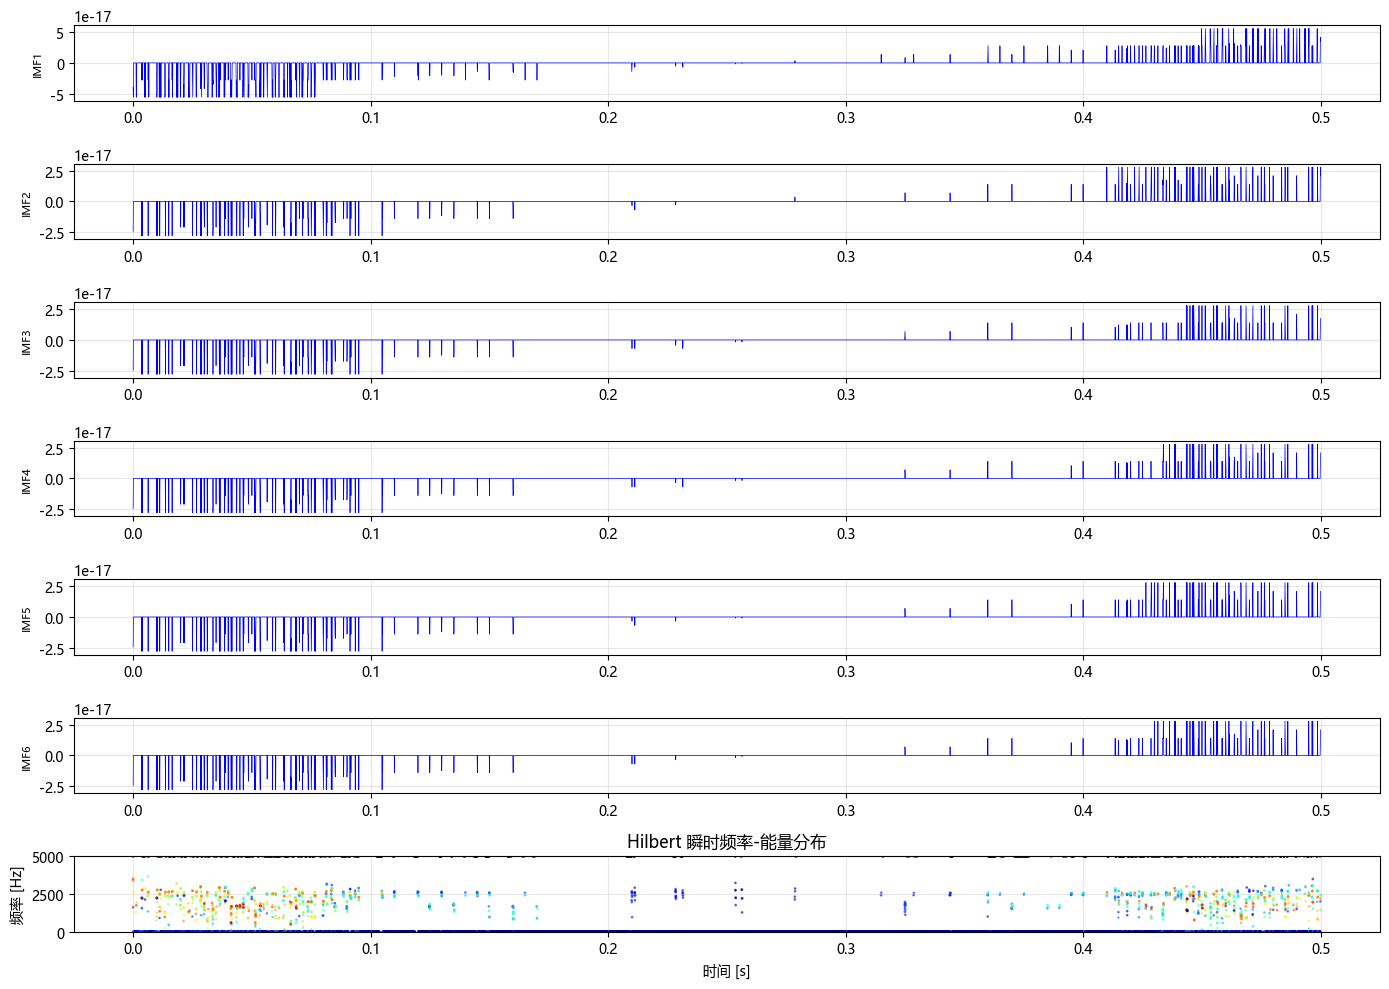

In [7]:
# ========================================
# 7. 算法5: HHT / EMD (希尔伯特-黄变换)
# ========================================

def simplified_emd(x, max_imf=5):
    """简化的EMD分解"""
    from scipy.signal import argrelextrema
    imfs = []
    residual = x.copy()
    
    for i in range(max_imf):
        try:
            maxima = argrelextrema(residual, np.greater)[0]
            minima = argrelextrema(residual, np.less)[0]
            if len(maxima) < 3 or len(minima) < 3:
                break
            # 简化：使用detrend作为IMF
            imf = residual - signal.detrend(residual)
            imfs.append(imf.copy())
            residual = residual - imf
        except:
            break
    
    if imfs:
        imfs.append(residual)  # 添加残差
        return np.array(imfs)
    return x.reshape(1, -1)

def plot_hht(x, fs, max_imf=6):
    """HHT时频分析"""
    x = preprocess_signal(x)
    imfs = simplified_emd(x, max_imf=max_imf)
    n_imf = min(len(imfs), 6)
    fig = plt.figure(figsize=(14, 10))
    t = np.arange(len(x)) / fs
    
    for i in range(n_imf):
        ax = plt.subplot(n_imf + 1, 1, i + 1)
        ax.plot(t, imfs[i], 'b-', linewidth=0.5)
        ax.set_ylabel('IMF%d' % (i+1), fontsize=8)
        ax.grid(True, alpha=0.3)
    
    ax = plt.subplot(n_imf + 1, 1, n_imf + 1)
    for i in range(min(4, n_imf)):
        try:
            analytic = hilbert(imfs[i])
            inst_phase = np.unwrap(np.angle(analytic))
            inst_freq = np.diff(inst_phase) / (2 * np.pi) * fs
            inst_amp = np.abs(analytic)[:-1]
            tp = np.linspace(0, t[-1], len(inst_freq))
            ax.scatter(tp, inst_freq, c=inst_amp, s=1, cmap='jet', alpha=0.5)
        except:
            pass
    
    ax.set_title('Hilbert 瞬时频率-能量分布')
    ax.set_xlabel('时间 [s]'); ax.set_ylabel('频率 [Hz]')
    ax.set_ylim([0, fs/2]); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

print('=' * 60)
print('HHT / EMD (希尔伯特-黄变换)')
print('=' * 60)
print('特点: 自适应分解，适合非平稳非线性信号')
print('参数max_imf: 建议4~6')
print('')
plot_hht(processed_signal, FS, max_imf=6)

S变换 (窗宽随频率自适应)
特点: 高频窄窗，低频宽窗
参数n_freqs: 频率点数，影响计算速度和分辨率



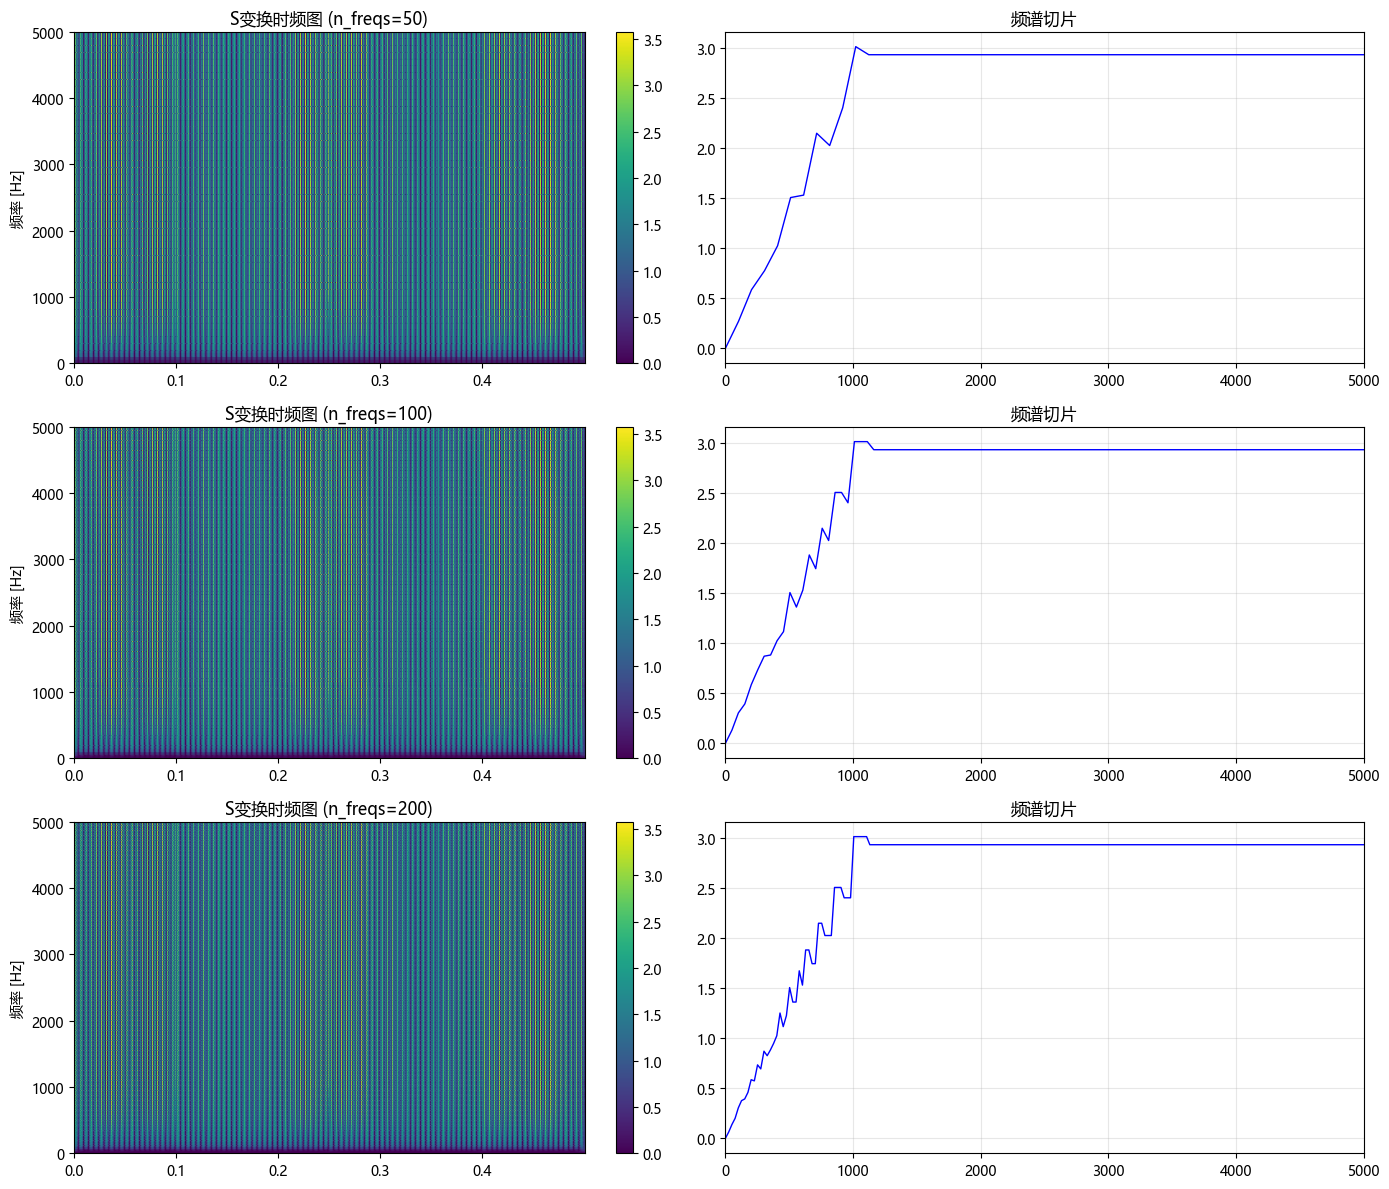

In [8]:
# ========================================
# 8. 算法6: S变换 (简化高效版)
# ========================================

def stockwell_transform_fast(x, fs, n_freqs=100):
    """
    S变换快速实现（基于STFT）
    参数n_freqs: 频率点数，范围32~256
    """
    x = preprocess_signal(x)
    N = len(x)
    t = np.arange(N) / fs
    freqs = np.linspace(0, fs/2, n_freqs)
    
    ST = np.zeros((n_freqs, N))
    
    for i, f in enumerate(freqs):
        if f < 1:
            ST[i, :] = np.mean(x)
        else:
            # 使用STFT代替完整S变换
            window_len = int(fs / f) if f > 0 else N
            window_len = max(8, min(window_len, N))
            window = signal.windows.gaussian(window_len, std=window_len/6)
            window = window / np.sum(window)
            
            # 卷积
            conv = np.convolve(x, window, mode='same')
            ST[i, :] = np.abs(conv)
    
    return t, freqs, ST

def plot_s_transform(x, fs, n_freqs_list=[50, 100, 200]):
    """S变换时频分析"""
    n = len(n_freqs_list)
    fig, axes = plt.subplots(n, 2, figsize=(14, 4*n))
    if n == 1: axes = axes.reshape(1, -1)
    t = np.arange(len(x)) / fs
    
    for i, n_freqs in enumerate(n_freqs_list):
        _, freqs, ST = stockwell_transform_fast(x, fs, n_freqs=n_freqs)
        im = axes[i, 0].pcolormesh(t, freqs, ST, shading='gouraud')
        axes[i, 0].set_title('S变换时频图 (n_freqs=%d)' % n_freqs)
        axes[i, 0].set_ylabel('频率 [Hz]'); axes[i, 0].set_ylim([0, fs/2])
        plt.colorbar(im, ax=axes[i, 0])
        
        slice_idx = len(t) // 2
        axes[i, 1].plot(freqs, ST[:, slice_idx], 'b-', linewidth=1)
        axes[i, 1].set_title('频谱切片'); axes[i, 1].set_xlim([0, fs/2])
        axes[i, 1].grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

print('=' * 60)
print('S变换 (窗宽随频率自适应)')
print('=' * 60)
print('特点: 高频窄窗，低频宽窗')
print('参数n_freqs: 频率点数，影响计算速度和分辨率')
print('')
plot_s_transform(processed_signal, FS, n_freqs_list=[50, 100, 200])

Wigner-Ville / Choi-Williams
WVD: 高分辨率，但有交叉项，适合单分量信号
CWD: 交叉项抑制好，适合多分量信号



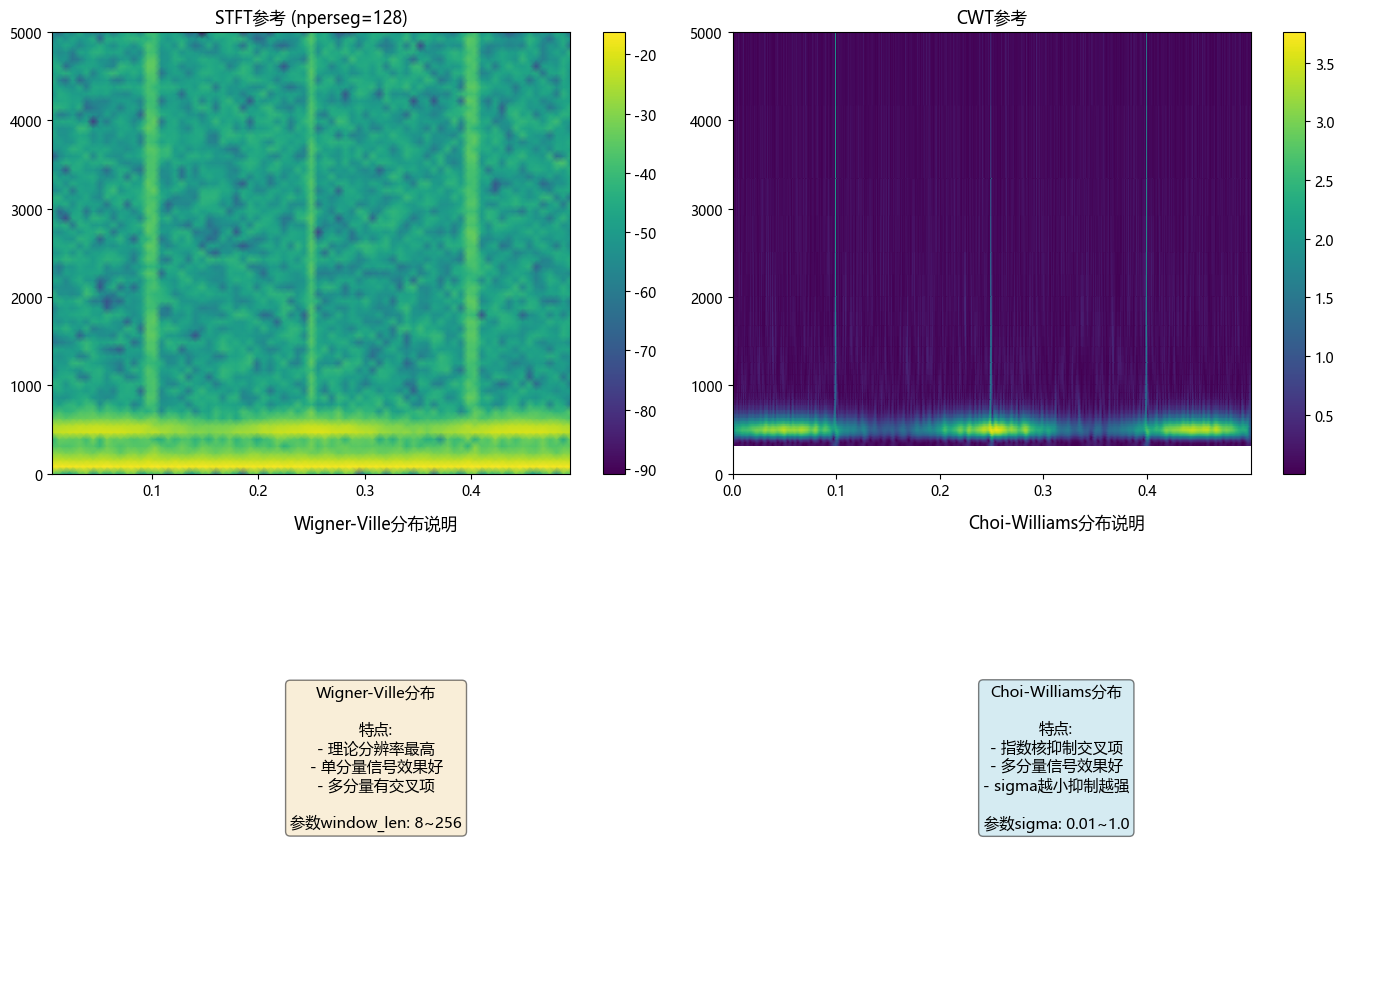

In [9]:
# ========================================
# 9. 算法7&8: Wigner-Ville / Choi-Williams 说明
# ========================================

def plot_bilinear_info(x, fs):
    """双线性时频分布说明"""
    x = preprocess_signal(x)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # STFT参考
    nperseg = 128
    f_stft, t_stft, Sxx = spectrogram(x, fs=fs, nperseg=nperseg, noverlap=nperseg//2)
    im = axes[0, 0].pcolormesh(t_stft, f_stft, 10*np.log10(Sxx+1e-12), shading='gouraud')
    axes[0, 0].set_title('STFT参考 (nperseg=%d)' % nperseg)
    plt.colorbar(im, ax=axes[0, 0])
    
    # CWT参考
    scales = np.arange(1, 32)
    coef, freqs = pywt.cwt(x, scales, 'cmor1.5-1.0', sampling_period=1.0/fs)
    t_wave = np.arange(len(x)) / fs
    im2 = axes[0, 1].pcolormesh(t_wave, freqs, np.abs(coef), shading='gouraud')
    axes[0, 1].set_title('CWT参考')
    axes[0, 1].set_ylim([0, fs/2]); plt.colorbar(im2, ax=axes[0, 1])
    
    axes[1, 0].text(0.5, 0.5, 
                    'Wigner-Ville分布\n\n特点:\n- 理论分辨率最高\n- 单分量信号效果好\n- 多分量有交叉项\n\n参数window_len: 8~256',
                    transform=axes[1, 0].transAxes, ha='center', va='center',
                    fontsize=11, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    axes[1, 0].set_title('Wigner-Ville分布说明'); axes[1, 0].axis('off')
    
    axes[1, 1].text(0.5, 0.5, 
                    'Choi-Williams分布\n\n特点:\n- 指数核抑制交叉项\n- 多分量信号效果好\n- sigma越小抑制越强\n\n参数sigma: 0.01~1.0',
                    transform=axes[1, 1].transAxes, ha='center', va='center',
                    fontsize=11, bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
    axes[1, 1].set_title('Choi-Williams分布说明'); axes[1, 1].axis('off')
    
    plt.tight_layout(); plt.show()

print('=' * 60)
print('Wigner-Ville / Choi-Williams')
print('=' * 60)
print('WVD: 高分辨率，但有交叉项，适合单分量信号')
print('CWD: 交叉项抑制好，适合多分量信号')
print('')
plot_bilinear_info(processed_signal, FS)

Gabor变换 (高斯窗STFT)
特点: 达到测不准原理下界
参数n_windows: 时间分辨率控制



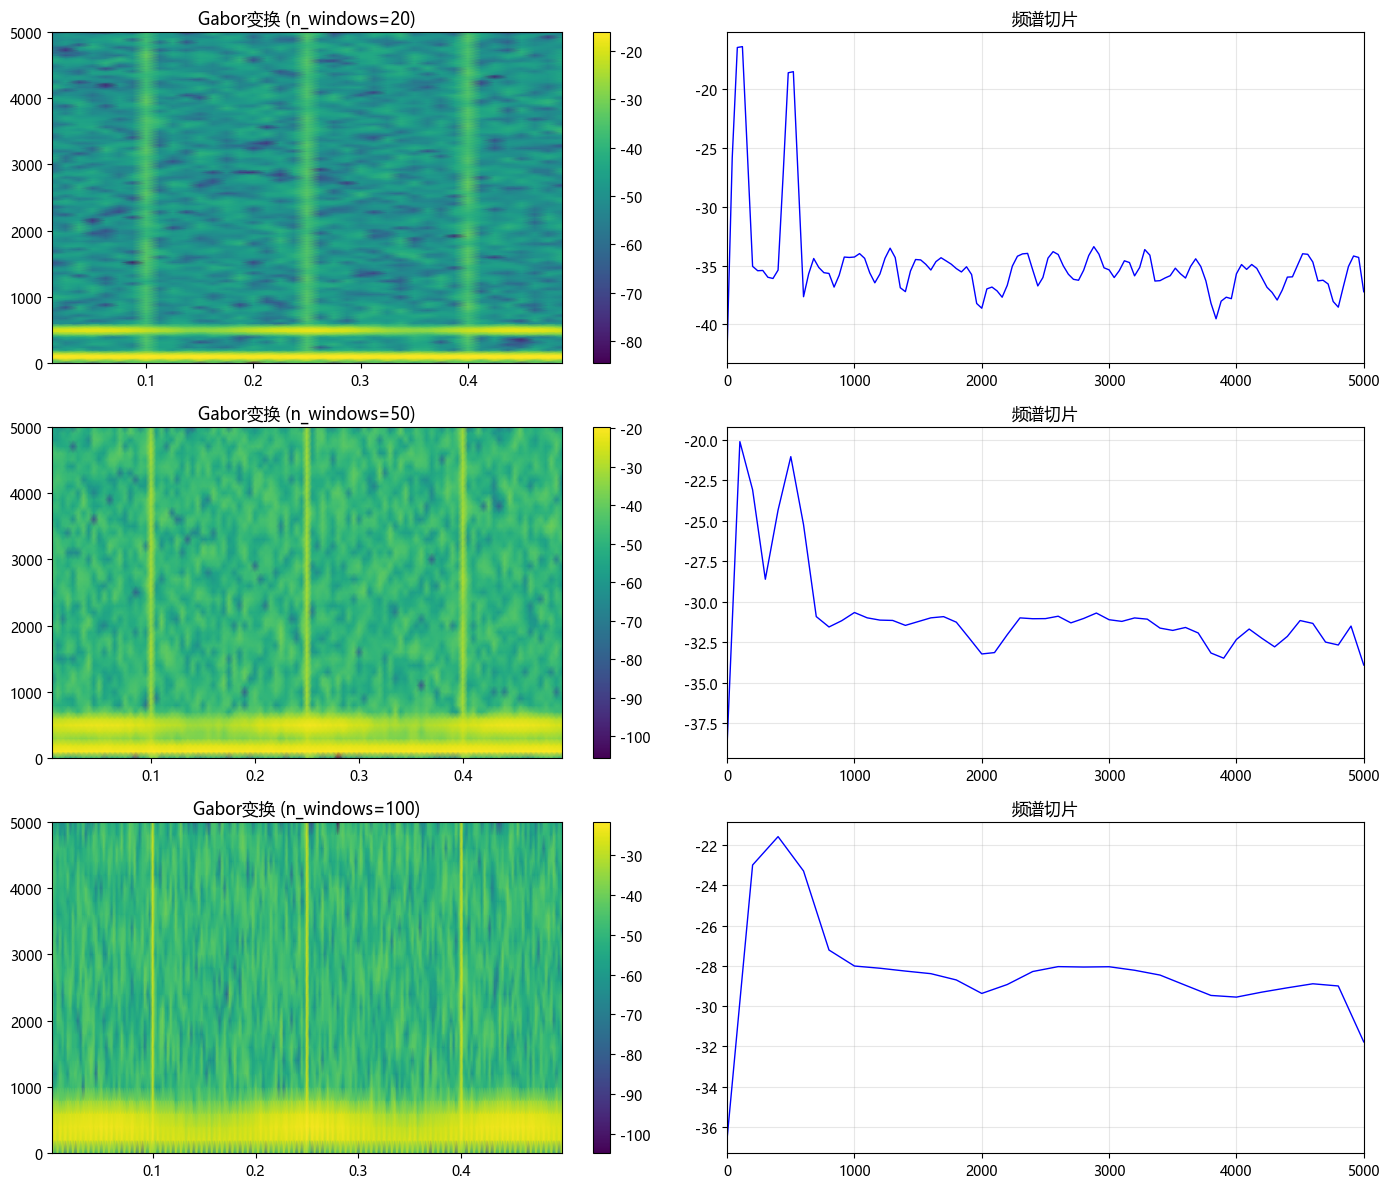

In [10]:
# ========================================
# 10. 算法9&12: Gabor变换
# ========================================

def gabor_transform_fast(x, fs, n_windows=50):
    """
    Gabor变换快速实现
    参数n_windows: 时间窗口数，范围20~200
    """
    x = preprocess_signal(x)
    N = len(x)
    freqs = np.fft.rfftfreq(N, d=1/fs)
    
    # 使用STFT代替完整Gabor
    nperseg = N // n_windows
    nperseg = max(16, min(nperseg, N))
    
    window = signal.windows.gaussian(nperseg, std=nperseg/6)
    f, t, Zxx = spectrogram(x, fs=fs, window=window, nperseg=nperseg, noverlap=nperseg//2)
    
    return t, f, np.abs(Zxx)

def plot_gabor(x, fs, n_windows_list=[20, 50, 100]):
    """Gabor变换对比"""
    fig, axes = plt.subplots(len(n_windows_list), 2, figsize=(14, 4*len(n_windows_list)))
    if len(n_windows_list) == 1: axes = axes.reshape(1, -1)
    
    for i, n_win in enumerate(n_windows_list):
        t_gab, f_gab, G = gabor_transform_fast(x, fs, n_windows=n_win)
        im = axes[i, 0].pcolormesh(t_gab, f_gab, 10*np.log10(G+1e-12), shading='gouraud')
        axes[i, 0].set_title('Gabor变换 (n_windows=%d)' % n_win)
        plt.colorbar(im, ax=axes[i, 0])
        
        slice_idx = len(t_gab) // 2
        axes[i, 1].plot(f_gab, 10*np.log10(G[:, slice_idx]+1e-12), 'b-', linewidth=1)
        axes[i, 1].set_title('频谱切片'); axes[i, 1].set_xlim([0, fs/2])
        axes[i, 1].grid(True, alpha=0.3)
    
    plt.tight_layout(); plt.show()

print('=' * 60)
print('Gabor变换 (高斯窗STFT)')
print('=' * 60)
print('特点: 达到测不准原理下界')
print('参数n_windows: 时间分辨率控制')
print('')
plot_gabor(processed_signal, FS, n_windows_list=[20, 50, 100])

希尔伯特谱 / 功率谱密度
Hilbert: 瞬时幅值和频率分析
Welch: nperseg越大，频率分辨率越高



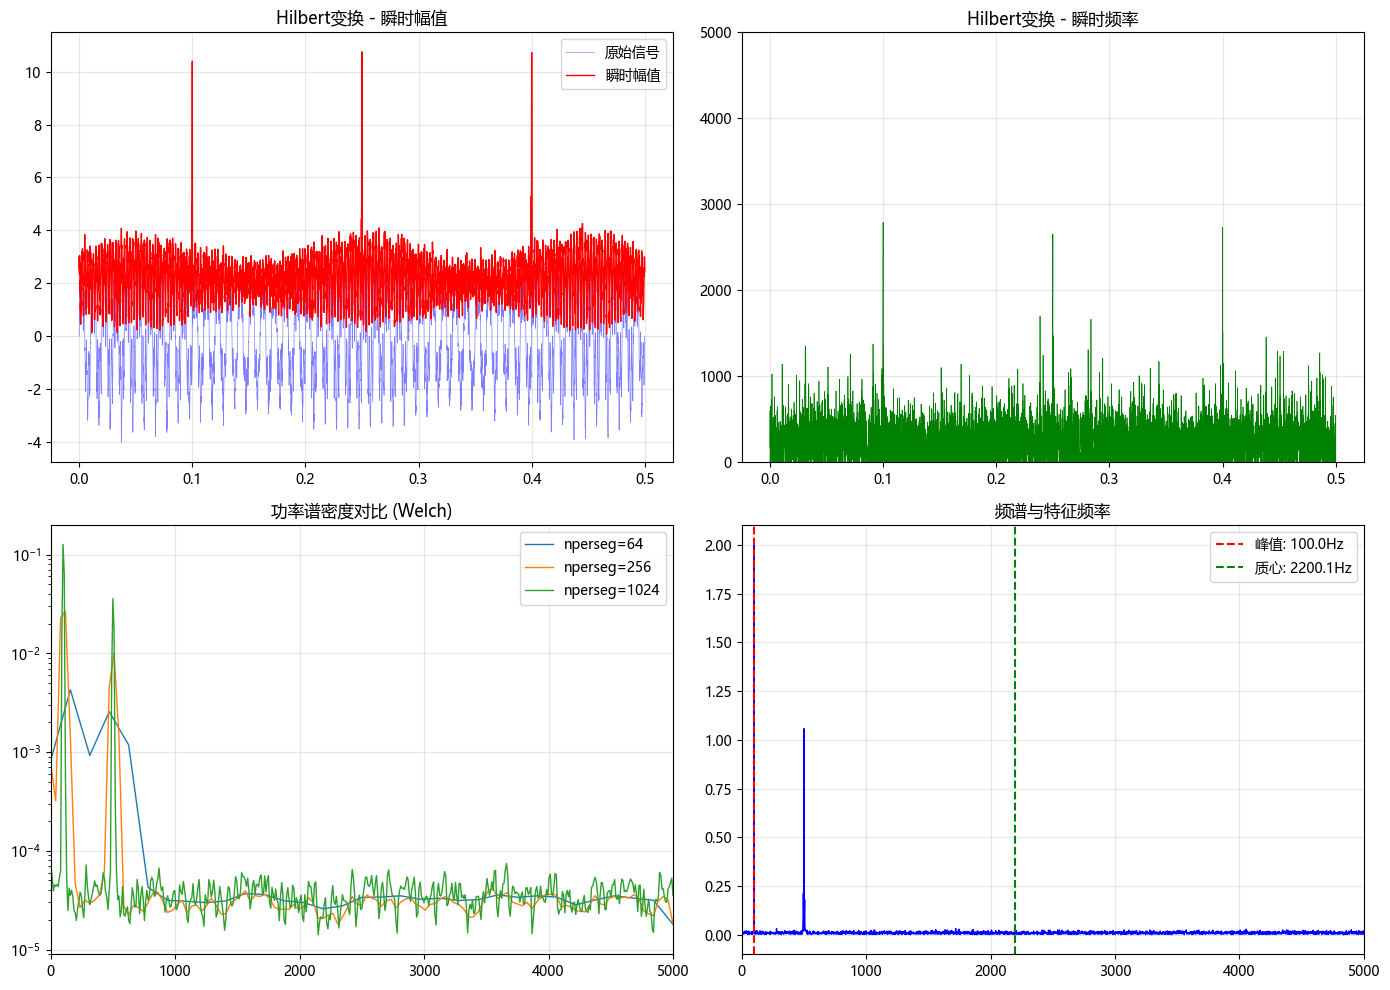

In [11]:
# ========================================
# 11. 算法10&13: 希尔伯特谱 / PSD
# ========================================

def plot_hilbert_psd(x, fs):
    """
    希尔伯特变换和功率谱密度
    Welch PSD参数nperseg: 64~4096
    """
    x = preprocess_signal(x)
    N = len(x)
    t = np.arange(N) / fs
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    analytic = hilbert(x)
    inst_amp = np.abs(analytic)
    inst_phase = np.unwrap(np.angle(analytic))
    inst_freq = np.diff(inst_phase) / (2*np.pi) * fs
    
    axes[0, 0].plot(t, x, 'b-', linewidth=0.5, alpha=0.5, label='原始信号')
    axes[0, 0].plot(t, inst_amp, 'r-', linewidth=1, label='瞬时幅值')
    axes[0, 0].set_title('Hilbert变换 - 瞬时幅值')
    axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].plot(t[:-1], inst_freq, 'g-', linewidth=0.5)
    axes[0, 1].set_title('Hilbert变换 - 瞬时频率')
    axes[0, 1].set_ylim([0, fs/2]); axes[0, 1].grid(True, alpha=0.3)
    
    nperseg_list = [64, 256, 1024]
    for nperseg in nperseg_list:
        f_psd, Pxx = welch(x, fs=fs, nperseg=nperseg, noverlap=nperseg//2)
        axes[1, 0].semilogy(f_psd, Pxx, linewidth=1, label='nperseg=%d' % nperseg)
    axes[1, 0].set_title('功率谱密度对比 (Welch)')
    axes[1, 0].set_xlim([0, fs/2]); axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)
    
    freqs = np.fft.rfftfreq(N, d=1/fs)
    fft_x = np.fft.rfft(x)
    mag = np.abs(fft_x) / N; mag[1:] *= 2
    peak_freq = freqs[np.argmax(mag[1:]) + 1]
    centroid = np.sum(freqs[1:] * mag[1:]) / np.sum(mag[1:])
    
    axes[1, 1].plot(freqs, mag, 'b-', linewidth=1)
    axes[1, 1].axvline(x=peak_freq, color='r', linestyle='--', label='峰值: %.1fHz' % peak_freq)
    axes[1, 1].axvline(x=centroid, color='g', linestyle='--', label='质心: %.1fHz' % centroid)
    axes[1, 1].set_title('频谱与特征频率')
    axes[1, 1].set_xlim([0, fs/2]); axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout(); plt.show()

print('=' * 60)
print('希尔伯特谱 / 功率谱密度')
print('=' * 60)
print('Hilbert: 瞬时幅值和频率分析')
print('Welch: nperseg越大，频率分辨率越高')
print('')
plot_hilbert_psd(processed_signal, FS)

短时自相关
用途: 准周期信号的瞬时周期估计
参数window_size: df = fs / window_size



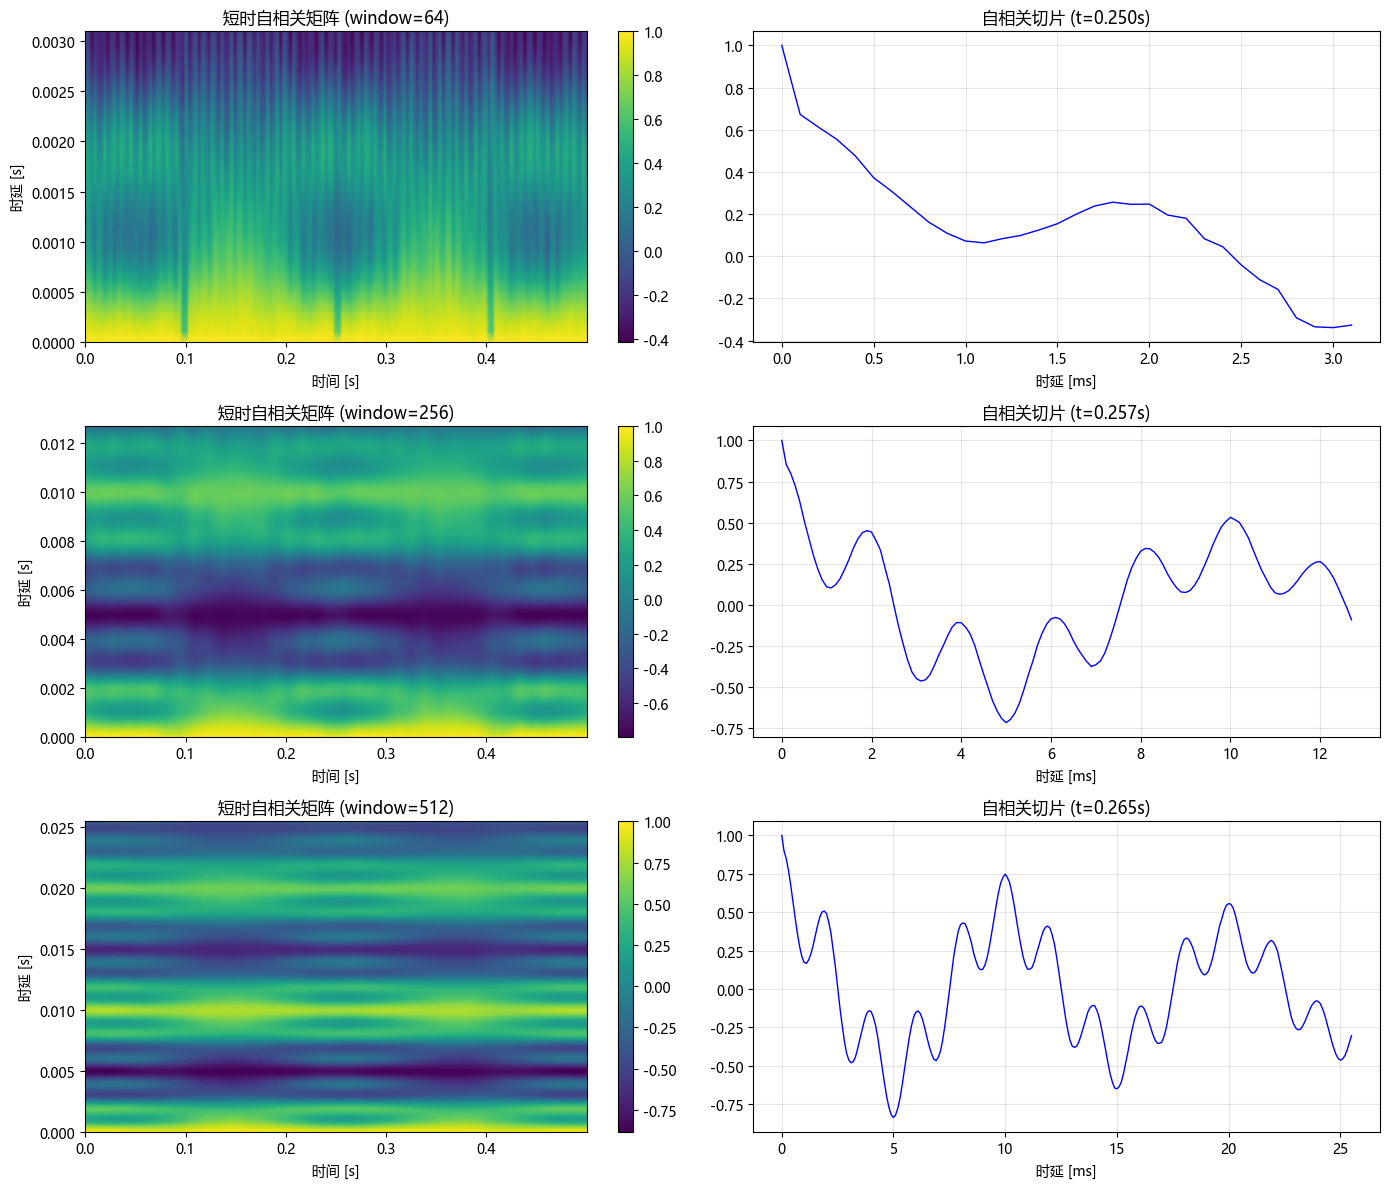

In [12]:
# ========================================
# 12. 算法11: 短时自相关
# ========================================

def short_time_autocorr(x, window_size=256, hop=128):
    """短时自相关，参数window_size: 64~2048"""
    x = preprocess_signal(x)
    N = len(x)
    n_windows = (N - window_size) // hop + 1
    max_lag = window_size // 2
    autocorr_matrix = np.zeros((n_windows, max_lag))
    
    for i in range(n_windows):
        start, end = i * hop, i * hop + window_size
        segment = x[start:end]
        corr = np.correlate(segment, segment, mode='full')
        corr = corr[len(corr)//2:len(corr)//2 + max_lag]
        corr = corr / corr[0]
        autocorr_matrix[i, :] = corr
    return autocorr_matrix

def plot_autocorr(x, fs, window_size_list=[64, 256, 512]):
    fig, axes = plt.subplots(len(window_size_list), 2, figsize=(14, 4*len(window_size_list)))
    if len(window_size_list) == 1: axes = axes.reshape(1, -1)
    t = np.arange(len(x)) / fs
    
    for i, ws in enumerate(window_size_list):
        hop = ws // 2
        ac_matrix = short_time_autocorr(x, window_size=ws, hop=hop)
        n_win = ac_matrix.shape[0]
        time_axis = np.linspace(0, t[-1], n_win)
        lag_axis = np.arange(ac_matrix.shape[1]) / fs
        
        im = axes[i, 0].pcolormesh(time_axis, lag_axis, ac_matrix.T, shading='gouraud')
        axes[i, 0].set_title('短时自相关矩阵 (window=%d)' % ws)
        axes[i, 0].set_xlabel('时间 [s]'); axes[i, 0].set_ylabel('时延 [s]')
        plt.colorbar(im, ax=axes[i, 0])
        
        slice_idx = n_win // 2
        axes[i, 1].plot(lag_axis * 1000, ac_matrix[slice_idx, :], 'b-', linewidth=1)
        axes[i, 1].set_title('自相关切片 (t=%.3fs)' % time_axis[slice_idx])
        axes[i, 1].set_xlabel('时延 [ms]'); axes[i, 1].grid(True, alpha=0.3)
    
    plt.tight_layout(); plt.show()

print('=' * 60)
print('短时自相关')
print('=' * 60)
print('用途: 准周期信号的瞬时周期估计')
print('参数window_size: df = fs / window_size')
print('')
plot_autocorr(processed_signal, FS)

---

# 参数调整总结

## 各算法参数范围

| 算法 | 参数 | 范围 | 说明 |
|------|------|------|------|
| STFT | nperseg | 16~65536 | 窗长 |
| STFT | noverlap | 0~nperseg-1 | 重叠 |
| CWT | wavelet | cmor*, mexh, gaus* | 小波基 |
| CWT | scales | 1~len(x)/4 | 尺度范围 |
| DWT/WPT | wavelet | db*, sym*, coif* | 小波基 |
| DWT/WPT | level | 1~log2(N) | 分解层数 |
| HHT | max_imf | 1~20 | IMF数量 |
| S变换 | n_freqs | 32~256 | 频率点数 |
| WVD | window_len | 8~256 | 平滑窗长 |
| CWD | sigma | 0.01~1.0 | 核参数 |
| Gabor | n_windows | 20~200 | 时间窗口数 |
| Welch PSD | nperseg | 64~4096 | 窗长 |
| 短时自相关 | window_size | 64~2048 | 分析窗长 |

## 重要提示
- **预处理**: 去直流 + 去趋势是防止近零Hz异常大值的关键步骤
- **STFT**: 时间分辨率和频率分辨率相互制约
- **CWT**: 小尺度对应高频，大尺度对应低频
- **DWT/WPT**: 层数越多频带划分越细
- **HHT**: 自适应分解，无需基函数